# DL_05 — Hybrid AML + DL Surrogate 

**Owner: Samarth Sangtani**  
**Work package 5 of 5 — Phase 1 XGBoost + Phase 2 U-Net**

## What this notebook does
Phase 1 XGBoost predicts one number per case (canopy-mean wind speed) from layout summaries. The Phase 2 U-Net predicts the pedestrian-level velocity *field*. The hybrid gives the U-Net the XGBoost number as a 6th, constant input channel, so the network gets global layout information that its small receptive field cannot easily compute by itself.



## 1. Paths (no torch yet)

In [16]:
import os
# Set before numpy/torch load. One thread is enough for this small dataset and avoids OpenMP clashes.
os.environ.setdefault("OMP_NUM_THREADS", "1")

import sys, json, subprocess, ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd().resolve()
ROOT = None
for candidate in [current, *current.parents]:
    if (candidate / "data" / "raw").is_dir() and (candidate / "Machine Learning Pipeline").is_dir():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the T006 repository.")

sys.path.insert(0, str(ROOT))
from dl_src.paths import get_project_paths      # pathlib only, safe to import before torch
PATHS = get_project_paths(ROOT)
DL_RESULTS, FIELDS_DIR, FIGURES_DIR, MODELS_DIR = PATHS["dl_results"], PATHS["fields"], PATHS["figures"], PATHS["models"]
print("Repository root:", ROOT)

Repository root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling


## 2. Phase 1 XGBoost → global context channel (separate process)

`python -m dl_src.hybrid` rebuilds the Phase 1 XGBoost (same features and parameters as ML_06) and writes one predicted canopy-mean value per case:

* **train cases:** out-of-fold, using `GroupKFold` over families, so a case is never predicted by a model that saw its own family;
* **validation/test cases:** the average of the five fold models, all fitted on training families only.

Running it as a subprocess keeps XGBoost and torch in different processes.

In [17]:
result = subprocess.run([sys.executable, "-m", "dl_src.hybrid", "--root", str(ROOT)],
                        cwd=ROOT, capture_output=True, text=True)
print(result.stdout[-1800:])
if result.returncode != 0:
    print(result.stderr[-3000:])
    raise RuntimeError("XGBoost step failed - read the message above.")

fold 1: fit on 8 families, predicted 2 unseen families
fold 2: fit on 8 families, predicted 2 unseen families
fold 3: fit on 8 families, predicted 2 unseen families
fold 4: fit on 8 families, predicted 2 unseen families
fold 5: fit on 8 families, predicted 2 unseen families
     split  n_cases  corr_pred_vs_actual  MAE_m_s  pred_std  channel_z_min  channel_z_max  n_unique_predictions
      test       42                0.870    0.435     0.944         -0.553          2.472                    28
     train      140                0.538    0.461     0.433         -0.934          1.225                   140
validation       42                0.973    0.456     0.982         -1.014          2.310                    42
{
  "test_cases": 42,
  "phase1_canopy_MAE_m_s": 0.4354458487091661,
  "phase1_canopy_RMSE_m_s": 0.6380604674916835,
  "phase1_canopy_R2": 0.7394988648783676
}



In [18]:
channel_table = pd.read_csv(DL_RESULTS / "hybrid_phase1_canopy_predictions.csv")
with open(DL_RESULTS / "hybrid_canopy_channel_stats.json") as f:
    CHANNEL_STATS = json.load(f)
with open(DL_RESULTS / "hybrid_phase1_scalar_test_metrics.json") as f:
    scalar_metrics = json.load(f)
channel_diag = pd.read_csv(DL_RESULTS / "hybrid_channel_diagnostics.csv")
CHANNEL_LOOKUP = dict(zip(channel_table["simulation_id"], channel_table["predicted_canopy_mean_m_s"]))

# Shuffled control: same values, but swapped between cases inside each split.
rng = np.random.default_rng(0)
SHUFFLED_LOOKUP = {}
for _, part in channel_table.groupby("split"):
    ids, vals = part["simulation_id"].to_numpy(), part["predicted_canopy_mean_m_s"].to_numpy().copy()
    rng.shuffle(vals)
    SHUFFLED_LOOKUP.update(dict(zip(ids, vals)))

print("Channel normalisation (true training target):", {k: round(v, 3) for k, v in CHANNEL_STATS.items() if k != "fit_scope"})
print("Phase 1 XGBoost on the DL test families (scalar target, m/s - NOT comparable with field error):")
print(json.dumps(scalar_metrics, indent=2))
display(channel_diag.round(3))

train_rng = channel_diag.set_index("split").loc["train", ["channel_z_min", "channel_z_max"]]
for split_name in ["validation", "test"]:
    row = channel_diag.set_index("split").loc[split_name]
    outside = row["channel_z_max"] > train_rng["channel_z_max"] + 1.5 or row["channel_z_min"] < train_rng["channel_z_min"] - 1.5
    print(f"{split_name}: channel range [{row['channel_z_min']:.2f}, {row['channel_z_max']:.2f}] vs train [{train_rng['channel_z_min']:.2f}, {train_rng['channel_z_max']:.2f}]",
          "-> WARNING: far outside the training range" if outside else "-> acceptable")

Channel normalisation (true training target): {'mean': 1.871, 'std': 0.828}
Phase 1 XGBoost on the DL test families (scalar target, m/s - NOT comparable with field error):
{
  "test_cases": 42,
  "phase1_canopy_MAE_m_s": 0.4354458487091661,
  "phase1_canopy_RMSE_m_s": 0.6380604674916835,
  "phase1_canopy_R2": 0.7394988648783676
}


,split,n_cases,corr_pred_vs_actual,MAE_m_s,pred_std,channel_z_min,channel_z_max,n_unique_predictions
0,test,42,0.870,0.435,0.944,-0.553,2.472,28
1,train,140,0.538,0.461,0.433,-0.934,1.225,140
2,validation,42,0.973,0.456,0.982,-1.014,2.310,42


validation: channel range [-1.01, 2.31] vs train [-0.93, 1.23] -> acceptable
test: channel range [-0.55, 2.47] vs train [-0.93, 1.23] -> acceptable


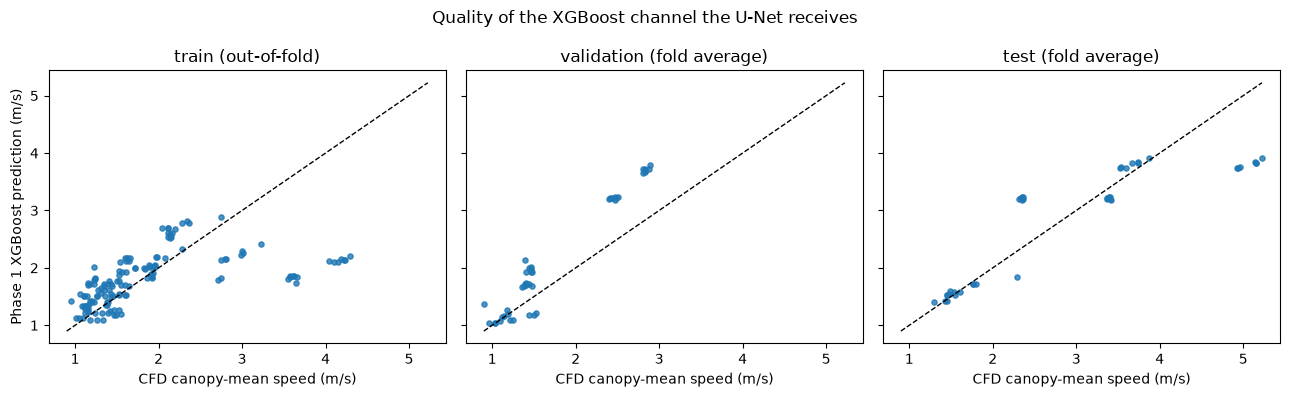

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, split_name in zip(axes, ["train", "validation", "test"]):
    part = channel_table[channel_table["split"] == split_name]
    ax.scatter(part["actual_canopy_mean_m_s"], part["predicted_canopy_mean_m_s"], s=14, alpha=0.8)
    lim = [channel_table[["actual_canopy_mean_m_s", "predicted_canopy_mean_m_s"]].min().min(),
           channel_table[["actual_canopy_mean_m_s", "predicted_canopy_mean_m_s"]].max().max()]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(f"{split_name} ({'out-of-fold' if split_name == 'train' else 'fold average'})")
    ax.set_xlabel("CFD canopy-mean speed (m/s)")
axes[0].set_ylabel("Phase 1 XGBoost prediction (m/s)")
fig.suptitle("Quality of the XGBoost channel the U-Net receives")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "hybrid_xgboost_channel_quality.png", dpi=160)
plt.show()

## 3. Load torch and the shared Phase 2 code

In [20]:
import random
import torch
from torch.utils.data import DataLoader
from dl_src.data import FlowFieldDataset, PHASE1_NUMERIC_FEATURES, PHASE1_CATEGORICAL_FEATURES
from dl_src.models import UNetVelocity, load_unet_checkpoint
from dl_src.training import train_model, get_torch_device
from dl_src.metrics import evaluate_model

# The XGBoost step lives in hybrid.py, which cannot import dl_src.data (torch). Check the lists still agree.
tree = ast.parse((ROOT / "dl_src" / "hybrid.py").read_text())
def literal(name):
    for node in tree.body:
        if isinstance(node, ast.Assign) and node.targets[0].id == name:
            return ast.literal_eval(node.value)
assert literal("PHASE1_NUMERIC_FEATURES") == PHASE1_NUMERIC_FEATURES, "numeric feature lists differ"
assert literal("PHASE1_CATEGORICAL_FEATURES") == PHASE1_CATEGORICAL_FEATURES, "categorical feature lists differ"

DEVICE = get_torch_device()
manifest = pd.read_csv(DL_RESULTS / "dl_case_metadata_manifest.csv")
split_manifest = pd.read_csv(DL_RESULTS / "dl_split_manifest.csv")
with open(DL_RESULTS / "normalization_stats.json") as f:
    normalization_stats = json.load(f)
print("Device:", DEVICE)
print({s: int((split_manifest.split == s).sum()) for s in ["train", "validation", "test"]}, "cases")

Device: mps
{'train': 140, 'validation': 42, 'test': 42} cases


## 4. Experiment settings

Everything except the input channels is identical to the DL_03 U-Net: base width 8, dropout 0.10, AdamW (lr 1e-3, weight decay 1e-4), gradient clipping 1.0, up to 25 epochs, patience 7, batch size 1.

* `SEEDS = [42]` is the quick version. For the report, three seeds (`[42, 43, 44]`) are much more convincing, because one run on three test families can easily mislead. Extra seeds retrain the base U-Net too.
* A run whose history file already exists is reloaded instead of retrained, so a crash does not cost you finished runs. Set `FORCE_RETRAIN = True` to override.

In [21]:
SEEDS = [42]                 # e.g. [42, 43, 44] for the final report
RUN_SHUFFLED_CONTROL = True  # negative control; set False to save time
FORCE_RETRAIN = False
EPOCHS, PATIENCE = 25, 7

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_loaders(lookup, seed):
    extra = {} if lookup is None else dict(canopy_predictions=lookup, canopy_prediction_stats=CHANNEL_STATS)
    data = {s: FlowFieldDataset(manifest, split_manifest, FIELDS_DIR, s, normalization_stats, **extra)
            for s in ["train", "validation", "test"]}
    generator = torch.Generator(); generator.manual_seed(seed)
    return {
        "train": DataLoader(data["train"], batch_size=1, shuffle=True, num_workers=0, generator=generator),
        "validation": DataLoader(data["validation"], batch_size=1, shuffle=False, num_workers=0),
        "test": DataLoader(data["test"], batch_size=1, shuffle=False, num_workers=0),
    }

def run_experiment(name, lookup, seed, in_channels):
    set_seed(seed)
    loaders = make_loaders(lookup, seed)
    config = {"in_channels": in_channels, "out_channels": 2, "base_channels": 8, "dropout": 0.10}
    finished = (MODELS_DIR / f"{name}_best.pt").exists() and (DL_RESULTS / f"{name}_training_history.csv").exists()
    if finished and not FORCE_RETRAIN:
        print(f"[{name}] finished run found - reloading")
        model, _ = load_unet_checkpoint(MODELS_DIR / f"{name}_best.pt", DEVICE)
    else:
        model = UNetVelocity(**config)
        model, _, _ = train_model(model=model, train_loader=loaders["train"], validation_loader=loaders["validation"],
                                  device=DEVICE, output_dir=DL_RESULTS, model_name=name, epochs=EPOCHS,
                                  learning_rate=1e-3, weight_decay=1e-4, patience=PATIENCE, gradient_clip=1.0,
                                  model_config=config)
    case_metrics, pooled, predictions = evaluate_model(model=model, data_loader=loaders["test"],
                                                       normalization_stats=normalization_stats, device=DEVICE,
                                                       model_name=name, results_dir=DL_RESULTS, fields_dir=FIELDS_DIR)
    return case_metrics, pooled, predictions

## 5. Train / reload the three model types on the same split

1. **Base U-Net** - 5 channels (seed 42 reuses the DL_03 checkpoint `unet_best.pt`).
2. **Hybrid U-Net** - 5 channels + real XGBoost channel.
3. **Shuffled-channel control** - 5 channels + XGBoost values assigned to the wrong cases. If this does as well as the hybrid, the gain is not about XGBoost information.

[unet] finished run found - reloading
hybrid_unet_seed42 | epoch 01/25 | train=0.641046 | validation=0.609074 | lr=1.00e-03
hybrid_unet_seed42 | epoch 02/25 | train=0.561675 | validation=0.517430 | lr=1.00e-03
hybrid_unet_seed42 | epoch 03/25 | train=0.506070 | validation=0.500361 | lr=1.00e-03
hybrid_unet_seed42 | epoch 04/25 | train=0.457733 | validation=0.445037 | lr=1.00e-03
hybrid_unet_seed42 | epoch 05/25 | train=0.416824 | validation=0.383866 | lr=1.00e-03
hybrid_unet_seed42 | epoch 06/25 | train=0.380013 | validation=0.389061 | lr=1.00e-03
hybrid_unet_seed42 | epoch 07/25 | train=0.347892 | validation=0.373243 | lr=1.00e-03
hybrid_unet_seed42 | epoch 08/25 | train=0.321185 | validation=0.359405 | lr=1.00e-03
hybrid_unet_seed42 | epoch 09/25 | train=0.298905 | validation=0.336928 | lr=1.00e-03
hybrid_unet_seed42 | epoch 10/25 | train=0.275379 | validation=0.339057 | lr=1.00e-03
hybrid_unet_seed42 | epoch 11/25 | train=0.264346 | validation=0.312354 | lr=1.00e-03
hybrid_unet_seed

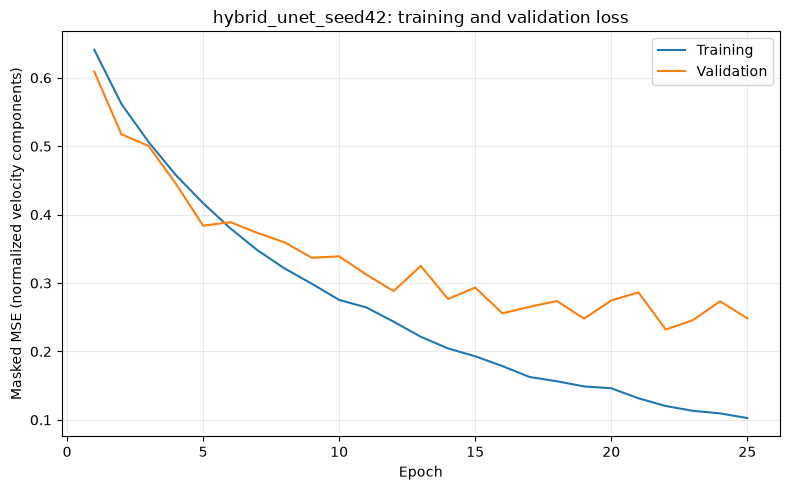

Best epoch: 22; best validation loss: 0.232034
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/hybrid_unet_seed42_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/hybrid_unet_seed42_training_history.csv
hybrid_shuffled_seed42 | epoch 01/25 | train=0.643980 | validation=0.625593 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 02/25 | train=0.571916 | validation=0.540430 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 03/25 | train=0.522899 | validation=0.521002 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 04/25 | train=0.468028 | validation=0.476714 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 05/25 | train=0.443453 | validation=0.408810 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 06/25 | train=0.401818 | validation=0.445088 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 07/25 | train=0.359289 | validation=0.364154 | lr=1.00e-03
hybrid_shuffled_seed42 | epoch 08/25 | train=0.308414 | validation=0.382130 | lr=1.0

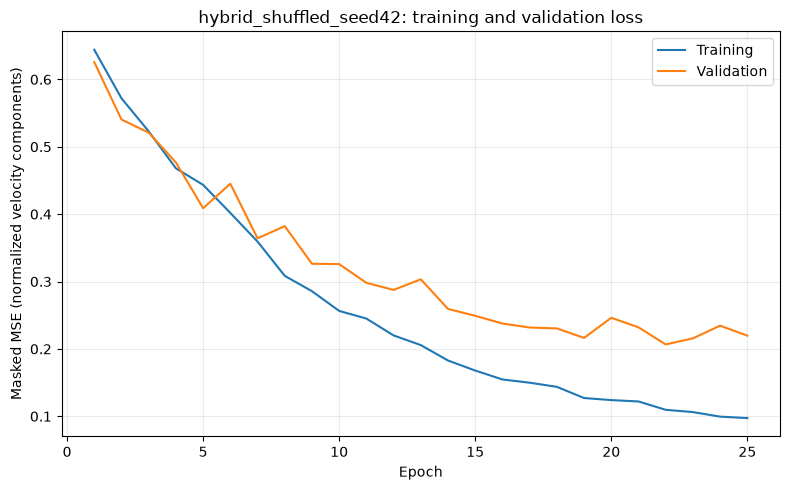

Best epoch: 22; best validation loss: 0.206640
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/hybrid_shuffled_seed42_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/hybrid_shuffled_seed42_training_history.csv
Finished: ['base/seed42', 'hybrid/seed42', 'shuffled_control/seed42']


In [22]:
runs = {}   # (kind, seed) -> dict(case=..., pooled=..., predictions=...)
for seed in SEEDS:
    base_name = "unet" if seed == 42 else f"unet_seed{seed}"
    plan = [("base", base_name, None, 5), ("hybrid", f"hybrid_unet_seed{seed}", CHANNEL_LOOKUP, 6)]
    if RUN_SHUFFLED_CONTROL:
        plan.append(("shuffled_control", f"hybrid_shuffled_seed{seed}", SHUFFLED_LOOKUP, 6))
    for kind, name, lookup, channels in plan:
        case_m, pooled, preds = run_experiment(name, lookup, seed, channels)
        runs[(kind, seed)] = dict(name=name, case=case_m, pooled=pooled, predictions=preds)
print("Finished:", [f"{k}/seed{s}" for k, s in runs])

## 6. Results on the held-out test families

In [23]:
rows = []
for (kind, seed), r in runs.items():
    p = r["pooled"].iloc[0]
    rows.append(dict(model=kind, seed=seed, field_MAE=p["field_component_MAE"], field_RMSE=p["field_component_RMSE"],
                     field_NRMSE=p["field_component_NRMSE"], speed_MAE=p["pedestrian_speed_MAE_native_units"]))
per_run = pd.DataFrame(rows)
summary = per_run.groupby("model")[["field_MAE", "field_RMSE", "field_NRMSE", "speed_MAE"]].agg(["mean", "std"]).round(4)
order = [k for k in ["base", "hybrid", "shuffled_control"] if k in per_run["model"].unique()]
summary = summary.loc[order]
base_mae = per_run.loc[per_run.model == "base", "field_MAE"].mean()
summary["MAE change vs base (%)"] = [round(100 * (base_mae - per_run.loc[per_run.model == k, "field_MAE"].mean()) / base_mae, 2) for k in order]
per_run.to_csv(DL_RESULTS / "hybrid_runs_per_seed.csv", index=False)
summary.to_csv(DL_RESULTS / "hybrid_vs_base_unet_field_metrics.csv")
display(per_run.round(4))
display(summary)
print("Positive 'change' = lower error than the base U-Net. (std is NaN when only one seed was run.)")

/var/folders/f_/zqxtpml925n3kgjl49j4jb7m0000gn/T/ipykernel_52089/240531161.py:11: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary["MAE change vs base (%)"] = [round(100 * (base_mae - per_run.loc[per_run.model == k, "field_MAE"].mean()) / base_mae, 2) for k in order]


,model,seed,field_MAE,field_RMSE,field_NRMSE,speed_MAE
0,base,42,0.2438,0.3416,0.1071,0.2431
1,hybrid,42,0.2527,0.3517,0.1103,0.2502
2,shuffled_control,42,0.2386,0.3426,0.1075,0.2410


field_MAE     field_RMSE     field_NRMSE     speed_MAE      \
                      mean std       mean std        mean std      mean std   
model                                                                         
base                0.2438 NaN     0.3416 NaN      0.1071 NaN    0.2431 NaN   
hybrid              0.2527 NaN     0.3517 NaN      0.1103 NaN    0.2502 NaN   
shuffled_control    0.2386 NaN     0.3426 NaN      0.1075 NaN    0.2410 NaN   

                 MAE change vs base (%)  
                                         
model                                    
base                               0.00  
hybrid                            -3.62  
shuffled_control                   2.15

Positive 'change' = lower error than the base U-Net. (std is NaN when only one seed was run.)


In [24]:
# Paired view: same test case, base vs hybrid. Less noisy than the pooled number alone.
family_of = dict(zip(split_manifest["simulation_id"], split_manifest["family_id"]))
paired = []
for seed in SEEDS:
    b = runs[("base", seed)]["case"].set_index("simulation_id")["field_component_MAE"]
    h = runs[("hybrid", seed)]["case"].set_index("simulation_id")["field_component_MAE"]
    d = pd.DataFrame({"base_MAE": b, "hybrid_MAE": h}); d["seed"] = seed
    d["improvement"] = d["base_MAE"] - d["hybrid_MAE"]
    d["family"] = d.index.map(family_of)
    paired.append(d.reset_index())
paired = pd.concat(paired)
paired.to_csv(DL_RESULTS / "hybrid_paired_case_comparison.csv", index=False)
print("Test cases where the hybrid is better:", f"{(paired.improvement > 0).mean():.0%}",
      f"({int((paired.improvement > 0).sum())} of {len(paired)})")
display(paired.groupby("family")[["base_MAE", "hybrid_MAE", "improvement"]].mean().round(4))

Test cases where the hybrid is better: 38% (16 of 42)


,base_MAE,hybrid_MAE,improvement
family,,,
A0625,0.3004,0.3178,-0.0173
A1111,0.1611,0.1552,0.0059
A4444,0.0809,0.0808,0.0000


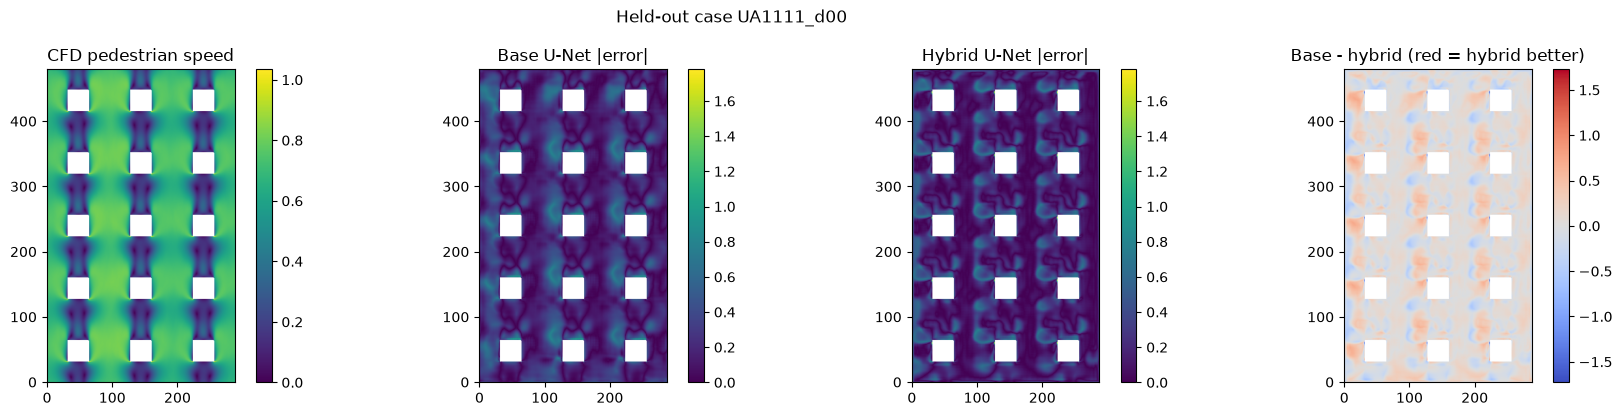

In [25]:
# Error maps for one test case (seed of the first run).
seed0 = SEEDS[0]
case_id = "UA1111_d00" if "UA1111_d00" in runs[("base", seed0)]["predictions"] else sorted(runs[("base", seed0)]["predictions"])[0]
def speed_error(pred):
    s_true = np.hypot(pred["u_true"], pred["v_true"]); s_pred = np.hypot(pred["u_pred"], pred["v_pred"])
    return np.ma.masked_where(~pred["mask"], np.abs(s_pred - s_true)), np.ma.masked_where(~pred["mask"], s_true)
base_err, true_speed = speed_error(runs[("base", seed0)]["predictions"][case_id])
hyb_err, _ = speed_error(runs[("hybrid", seed0)]["predictions"][case_id])
vmax = float(max(base_err.max(), hyb_err.max()))
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
panels = [(true_speed, "CFD pedestrian speed", None), (base_err, "Base U-Net |error|", vmax),
          (hyb_err, "Hybrid U-Net |error|", vmax), (base_err - hyb_err, "Base - hybrid (red = hybrid better)", None)]
for a, (img, title, vm) in zip(ax, panels):
    cmap = "coolwarm" if "Base -" in title else "viridis"
    lim = float(np.abs(img).max()) if "Base -" in title else vm
    im = a.imshow(img, origin="lower", cmap=cmap, vmin=(-lim if "Base -" in title else 0), vmax=lim)
    a.set_title(title); fig.colorbar(im, ax=a, fraction=0.046)
fig.suptitle(f"Held-out case {case_id}")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "hybrid_vs_base_error_maps.png", dpi=160); plt.show()

## 7. Verdict (generated from the numbers above)

In [26]:
m = per_run.groupby("model")["field_MAE"].mean()
rel = lambda k: 100 * (m["base"] - m[k]) / m["base"]
print(f"Base U-Net field MAE       : {m['base']:.4f}")
print(f"Hybrid U-Net field MAE     : {m['hybrid']:.4f}  ({rel('hybrid'):+.2f}% vs base)")
if "shuffled_control" in m:
    print(f"Shuffled-channel control   : {m['shuffled_control']:.4f}  ({rel('shuffled_control'):+.2f}% vs base)")
print()
NOISE = 3.0   # % - below this we do not call a difference real with so few test families
if rel("hybrid") > NOISE and ("shuffled_control" not in m or m["hybrid"] < m["shuffled_control"]):
    print("The hybrid beats the base U-Net AND the shuffled control: the XGBoost channel carries useful information.")
elif rel("hybrid") > NOISE:
    print("The hybrid beats the base U-Net but the shuffled control does about as well: the gain is probably")
    print("from having an extra input or from training noise, not from the XGBoost information itself.")
elif rel("hybrid") < -NOISE:
    print("The hybrid is WORSE than the base U-Net. Report this honestly and discuss why (see Section 8).")
else:
    print(f"No difference larger than {NOISE:.0f}% - the hybrid neither helps nor hurts on this test set.")
if len(SEEDS) < 3:
    print(f"\nOnly {len(SEEDS)} seed(s): treat this as indicative. Use SEEDS = [42, 43, 44] for the final numbers.")

Base U-Net field MAE       : 0.2438
Hybrid U-Net field MAE     : 0.2527  (-3.62% vs base)
Shuffled-channel control   : 0.2386  (+2.15% vs base)

The hybrid is WORSE than the base U-Net. Report this honestly and discuss why (see Section 8).

Only 1 seed(s): treat this as indicative. Use SEEDS = [42, 43, 44] for the final numbers.


## 8. How to read and discuss the result

* **Why it might help:** plan-area density (the main driver of canopy speed in Phase 1) is a *global* property. A U-Net with four poolings sees a limited window of the domain, so the XGBoost value hands it that global summary.
* **Why it might not:** the test families are the lowest- and highest-density layouts (A0625, A1111, A4444), so XGBoost has to extrapolate and tree models cannot extrapolate beyond the densities they saw. On the test set its scalar R² is about 0.74, compared with 0.90 in the Phase 1 5-fold CV. The U-Net also already receives `u_tau`, which is a monotone function of density in this dataset.
* **Different targets:** the XGBoost target is canopy-mean speed (ground to roof height); the U-Net target is the pedestrian-level (1.75 m) field. The channel is a *hint*, not a constraint, and the scalar MAE (m/s) must never be placed next to the field MAE.
* **Small data:** 16 families (10 train / 3 validation / 3 test). One seed and three test families cannot prove a small improvement. Say so in the report.
* **Not physics-informed:** nothing here enforces Navier–Stokes or mass conservation.

## DL_05 completion checklist
- [ ] `python -m dl_src.hybrid` ran and the diagnostics table shows val/test channel ranges close to the train range.
- [ ] Base, hybrid and shuffled control evaluated on the same 42 test cases.
- [ ] Final numbers use three seeds, or the report clearly says "single seed".
- [ ] Field metrics and scalar metrics reported separately.
- [ ] Result described honestly, whether the hybrid helped, matched or hurt.